# Fuzzy number matching with the PyMuPDF Grounding Skill

An AI model often writes a number differently from the document it quotes. The contract says "fourteen days", the answer quotes "14 days", and an exact text search finds nothing, so a correct citation looks unsupported.

This notebook shows how `fuzzy=True` in [the PyMuPDF grounding skill](https://pymupdf.io/grounding/skill) treats numbers written as digits and as words as equal, while every other word still has to match. Tested with PyMuPDF 2.1.

In [1]:
%pip install -q pymupdf


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Load the grounding skill

The helpers live in [`scripts/grounding.py`](https://github.com/pymupdf/cookbook/tree/main/skills/grounding-skill/scripts). If you run this notebook inside a clone of the cookbook repository, the local copy is used; otherwise it is downloaded from GitHub.

In [2]:
import os
import sys
import urllib.request

LOCAL = "../skills/grounding-skill/scripts/grounding.py"
URL = "https://raw.githubusercontent.com/pymupdf/cookbook/main/skills/grounding-skill/scripts/grounding.py"

if os.path.exists(LOCAL):
    sys.path.insert(0, os.path.dirname(LOCAL))
else:
    urllib.request.urlretrieve(URL, "grounding.py")

import grounding
from grounding import locate, snippet, to_json

## Sample document

A one-page services agreement that writes every number in words, as contracts and policies often do. Replace `path` with your own PDF to try it on real documents; it needs a text layer.

In [3]:
import pymupdf

text = """Northwind Services Agreement

1. Term. This agreement runs for twenty-four months from the effective date and renews for further periods of twelve months unless either party gives ninety days' written notice.

2. Fees. The annual fee is two hundred and fifty thousand dollars, rising by three per cent each year.

3. Refunds. Refunds are issued within fourteen days of a valid request.

4. Service levels. The provider will respond to critical incidents within four hours and maintain availability of ninety-nine per cent.

5. Support. Support is provided in three eight-hour shifts, five days a week.

6. Records. Records are retained for seven years after termination."""

doc = pymupdf.open()
page = doc.new_page()
page.insert_textbox(pymupdf.Rect(72, 72, 523, 770), text, fontsize=11, fontname="helv")
doc.save("northwind_agreement.pdf")

path = "northwind_agreement.pdf"
doc = pymupdf.open(path)
page = doc[0]

## The problem: digits in the quote, words on the page

Suppose a model answered "How long do refunds take?" and quoted the agreement as "Refunds are issued within 14 days". The claim is correct, but the default search compares the text literally:

In [4]:
quote = "Refunds are issued within 14 days"
locate(page, quote)

[]

Nothing is found. Without number matching, this citation would be reported as unsupported and sent for review, or worse, counted as a hallucination.

## Turn on fuzzy number matching

Pass `fuzzy=True`. The quote is now found, and the quads cover the words as printed on the page, "fourteen" included:

In [5]:
quads = locate(page, quote, fuzzy=True)
print(len(quads), "quads")
print(to_json([{"claim": None, "cited_text": quote, "doc": 0, "page": 0, "quads": quads}])[0])

6 quads
{'claim': None, 'cited_text': 'Refunds are issued within 14 days', 'found': True, 'page_number': 1, 'rect': [131.3, 202.0, 327.0, 217.1]}


`fuzzy=True` only affects `locate()`'s fallback. The exact `Page.search_for()` runs first, so quotes that match word for word behave exactly as before, and the number rules apply only when that search finds nothing.

## What fuzzy matching recognises

Before comparing, both the quote and the page text are normalised: each run of number words becomes one number. Quotes from the model, all written with digits:

In [6]:
quotes = [
    "runs for 24 months from the effective date",            # twenty-four
    "periods of 12 months unless either party gives 90 days' written notice",
    "The annual fee is 250,000 dollars, rising by 3% each year",  # two hundred and fifty thousand, three per cent
    "The annual fee is 250 thousand dollars",                # digits followed by a scale word
    "maintain availability of 99 percent",                   # ninety-nine per cent
    "Support is provided in 3 8-hour shifts, 5 days a week",  # eight-hour, kept apart from three
    "Records are retained for 7 years after termination",
]

print(f"{'quote':72} default  fuzzy")
for q in quotes:
    print(f"{q:72} {bool(locate(page, q))!s:8} {bool(locate(page, q, fuzzy=True))}")

quote                                                                    default  fuzzy
runs for 24 months from the effective date                               False    True
periods of 12 months unless either party gives 90 days' written notice   False    True
The annual fee is 250,000 dollars, rising by 3% each year                False    True
The annual fee is 250 thousand dollars                                   False    True
maintain availability of 99 percent                                      False    True
Support is provided in 3 8-hour shifts, 5 days a week                    False    True
Records are retained for 7 years after termination                       False    True


The default search finds none of them; fuzzy matching finds all of them. In summary:

| Written on the page | Matches in the quote |
|---|---|
| fourteen, seven | 14, 7 |
| twenty-four, ninety-nine (also split across a line end) | 24, 99 |
| two hundred and fifty thousand | 250,000 or 250000 or 250 thousand |
| three per cent, ninety-nine percent | 3%, 99%, 3 percent |
| eight-hour | 8-hour |

It works in both directions: a quote that spells out a number finds digits on the page.

## It stays strict about the value

Fuzzy matching changes how a number may be written, not which number it is. A wrong number is still not found, and two numbers written next to each other are not merged into one:

In [7]:
wrong = [
    "Refunds are issued within 30 days",          # the page says fourteen
    "maintain availability of 99.9%",             # the page says ninety-nine per cent
    "Support is provided in 38-hour shifts",      # three eight-hour shifts is 3 and 8, not 38
    "renews for further periods of 24 months",    # the page says twelve
]
for q in wrong:
    print(f"{q:48} fuzzy={bool(locate(page, q, fuzzy=True))}")

Refunds are issued within 30 days                fuzzy=False
maintain availability of 99.9%                   fuzzy=False
Support is provided in 38-hour shifts            fuzzy=False
renews for further periods of 24 months          fuzzy=False


Punctuation also ends a number, so "five, six" stays two numbers. This is what makes `fuzzy=True` safe for verification: a model that changed 14 to 30 is still caught.

## Show the evidence

The quads point at the words as printed, so the evidence image highlights "fourteen days" even though the model wrote "14 days":

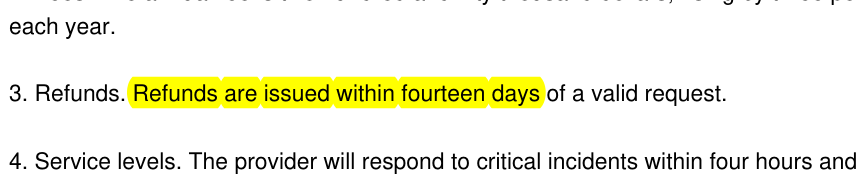

In [8]:
from IPython.display import Image

result = {"claim": "Refunds take 14 days.", "cited_text": quote, "doc": 0, "page": 0, "quads": quads}
Image(snippet([doc], result).tobytes("png"))

## With Claude citations

`ground_citations()` takes the same flag:

```python
results = grounding.ground_citations(response, [doc], fuzzy=True)
```

Claude's `cited_text` is copied from the document, so it usually matches without help. Fuzzy matching matters most where the model writes the quote itself: prompt-based citations from any model, agent outputs, and values extracted into structured fields.

## From the command line

The helper script has a `--fuzzy` flag. It prints the page and rectangle, and exits with 1 when the quote is not found:

In [9]:
!"{sys.executable}" "{grounding.__file__}" {path} --quote "within 14 days" --fuzzy

{
  "claim": null,
  "cited_text": "within 14 days",
  "found": true,
  "page_number": 1,
  "rect": [
    229.1,
    202.0,
    327.0,
    217.1
  ]
}


## Limits to know

- Only numbers are normalised. A paraphrased quote is still not found, and that is deliberate: the skill's rule is not to loosen matching to force a result.
- Not covered: ordinals ("first" and "1st"), decimals in words ("four point one"), fractions ("half"), and currency words ("dollars" and "$").
- "one" is read as a number everywhere, on both sides, so "the one that" still matches itself; it only matters if a quote writes "1" where the page means the pronoun.
- Numbers are compared by value, not by format: "250,000" and "250000" are the same number.

## Next steps

- [The PyMuPDF grounding skill](https://github.com/pymupdf/cookbook/blob/main/skills/grounding-skill/SKILL.md)
- Use `fuzzy=True` in the citation check from [Catch Hallucinated Citations](https://pymupdf.io/blog/catch-hallucinated-citations), so spelled-out numbers are not reported as close matches.
- See everything on grounding with PyMuPDF: https://pymupdf.io/grounding